In [12]:
%pip install plotly
%pip install gurobipy

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objs as go
import gurobipy as gp
from gurobipy import GRB

###**3D POLYTOPE**

The complexity of increasing the number of variables.

In [14]:
# 3d polytope
# Define the equations of the model
A = np.array([
    [1, 1, 1],
    [1, -1, 1],
    [-1, 0, 0],
    [0, 0, -1],
])
b = np.array([10, 5, 0, 0])


# Define the data for the plot
data = [
    go.Scatter3d(x=A[:, 0], y=A[:, 1], z=A[:, 2], mode='markers', name='Points'),
    go.Mesh3d(
        x=A[:, 0],
        y=A[:, 1],
        z=A[:, 2],
        opacity=0.5,
        color='lightblue',
        name='Convex Hull',
    ),
]

# Define the layout for the plot
layout = go.Layout(
    title='Convex Hull (Model)',
    scene=dict(
        xaxis=dict(title='x'),
        yaxis=dict(title='y'),
        zaxis=dict(title='z'),
    ),
)

# Create the plot and display it
fig = go.Figure(data=data, layout=layout)
fig.show()

###**Furniture Factory Problem**

Determine the optimal production plan for a furniture factory that produces a variety of products using a set of limited resources.

### Decision Variables

$x_{1} \geq 0$: Number of chairs.
$x_{2} \geq 0$: Number of tables.

### Objective Function(s)

- **Max revenue**. We seek to maximize the total revenue.

\begin{equation}
\text{Max} \quad Z = 45 x_{1} + 80 x_{2}
\tag{0}
\end{equation}

### Constraints

- **Wood**

\begin{equation}
5 x_{1} + 20 x_{2} \leq 400
\tag{1}
\end{equation}

- **Labor**

\begin{equation}
10 x_{1} + 15 x_{2} \leq 450
\tag{2}
\end{equation}

- **Pos**

\begin{equation}
x_{1}, x_{2} \geq 0
\tag{3}
\end{equation}

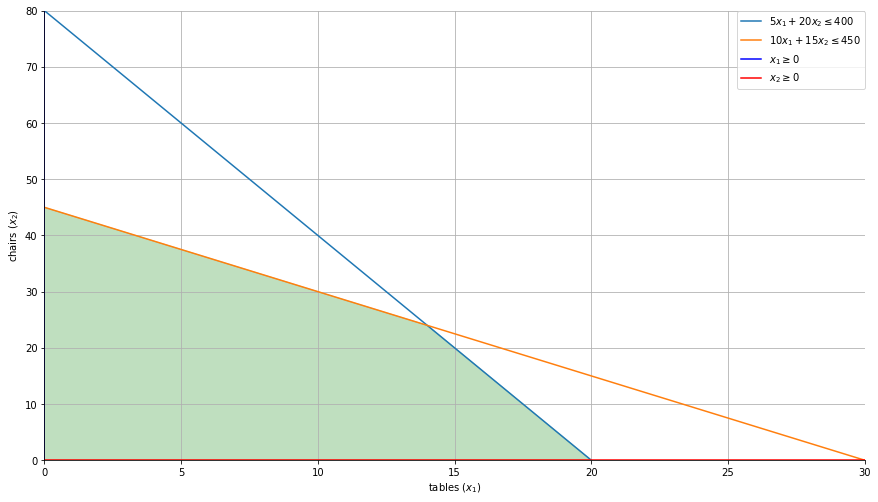

In [15]:
# Plot sol. space
x_1 = np.linspace(0, 100, 1000)
x_2 = np.linspace(0, 100, 1000)

# plot
fig, ax = plt.subplots()
fig.set_size_inches(14.7, 8.27)

# draw constraints
plt.plot(x_1, (400-(x_1*20))/5.0, label=r'$5 x_1 + 20 x_2 \leq 400$') # constraint 1
plt.plot(x_1, (450-(x_1*15))/10.0, label=r'$10 x_1 + 15 x_2 \leq 450$') # constraint 2
plt.axvline(0, color='b', label=r'$x_1 \geq 0$') # constraint 3
plt.axhline(0, color='r', label=r'$x_2 \geq 0$') # constraint 4


plt.xlim((0, 30))
plt.ylim((0, 80))
plt.xlabel(r'tables ($x_1$)')
plt.ylabel(r'chairs ($x_2$)')

# fill in the fesaible region
plt.fill_between(x_1, np.minimum((400-(x_1*20))/5.0, (450-(x_1*15))/10.0), np.minimum((400-(x_1*20))/5.0, 0), 
where=x_1 >= 0,
color='green', alpha=0.25)
plt.legend(bbox_to_anchor=(1, 1), loc=1, borderaxespad=0.)

# Hide the right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.grid(True)
plt.show()

In [16]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 450

# Create the Gurobi model
model = gp.Model()
# model = gp.read('mod_1.mps') # This is the correct use when reading an LP (note: MPS > LP)

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# model.read('mod_1.mps') # Not the correct use when reading an LP

# Optimize the model
model.optimize()

# Write MPS format
# model.write('mod_1.mps')
# Write LP format
# model.write('mod_1.lp')



# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 2 columns and 4 nonzeros
Model fingerprint: 0xd0437183
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+02]
Presolve time: 0.01s
Presolved: 2 rows, 2 columns, 4 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    6.5000000e+31   2.968750e+30   6.500000e+01      0s
       2    2.2000000e+03   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.01 seconds (0.00 work units)
Optimal objective  2.200000000e+03

Optimal objective value: 2200.00
The factory need to produce 24.000000 chairs
The factory need to produce 14.000000 tables


###**Sensitivity analysis of LP problems**

- Solving LP problems provides more information than only the values of the decision variables and the value of the objective function.

- Associated with an LP optimal solution there are **shadow prices**
(a.k.a. dual variables, or marginal values) for the constraints.

- The shadow price of a constraint associated with the optimal solution, represents the change in the value of the objective function per unit of increase in the righthand side value of that constraint.

- There are shadow prices associated with the non-negativity constraints. These shadow prices are called the **reduced costs**.


###**Economic interpretation (LABOR)**

- For example, suppose the labor capacity is increased from 450 hours to 451 hours. What is the increase in the objective function value from such increase?
- Since the constraints on wood capacity (1) and labor capacity (2) define the optimal solution, we can solve the following system of equations

- **Wood**

\begin{equation}
5 x_{1} + 20 x_{2} \leq 400
\end{equation}

- **Labor**

\begin{equation}
10 x_{1} + 15 x_{2} \leq 451
\end{equation}


In [17]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 451

# Create the Gurobi model
model = gp.Model()

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 2 columns and 4 nonzeros
Model fingerprint: 0x48a410c8
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 5e+02]
Presolve time: 0.02s
Presolved: 2 rows, 2 columns, 4 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    6.5000000e+31   2.968750e+30   6.500000e+01      0s
       2    2.2040000e+03   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.03 seconds (0.00 work units)
Optimal objective  2.204000000e+03

Optimal objective value: 2204.00
The factory need to produce 24.160000 chairs
The factory need to produce 13.960000 tables


###**Analysis**

- The new values of the decision variables are: chairs (x1) = 24.16, tables (x2) = 13.96
- The new value of the objective function (revenue) is = \$2,204
- The **shadow price** associated with the labor capacity is \$2,204 - \$2,200 = \$4. That is, we can get $4 of increased revenue per hour of increase in labor capacity. 
- **Remark:** The **shadow price** value of \$4 remains constant over a range of value changes of the wood capacity. The calculation of this range is beyond the scope of this course.

###**Economic interpretation (WOOD)**

- Similarly, we can compute the shadow price of the mahogany constraint by solving the following system of equations.

- **Wood**

\begin{equation}
5 x_{1} + 20 x_{2} \leq 401
\end{equation}

- **Labor**

\begin{equation}
10 x_{1} + 15 x_{2} \leq 450
\end{equation}

In [18]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 401
max_labor = 450

# Create the Gurobi model
model = gp.Model()

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 2 columns and 4 nonzeros
Model fingerprint: 0xea5b2414
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+02]
Presolve time: 0.01s
Presolved: 2 rows, 2 columns, 4 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    6.5000000e+31   2.968750e+30   6.500000e+01      0s
       2    2.2010000e+03   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.03 seconds (0.00 work units)
Optimal objective  2.201000000e+03

Optimal objective value: 2201.00
The factory need to produce 23.880000 chairs
The factory need to produce 14.080000 tables


###**Analysis**
- The new values of the decision variables are: chairs (x1) = 23.88, tables (x2) = 14.08. 
- The new value of the objective function (revenue) is = \$2,201
- The shadow price associated with the wood capacity is \$2,201 - \$2,200 = \$1.
- That is, we can get \$1 of increased revenue per unit of increase in wood
capacity.
- **Remark:** The shadow price value of \$1 remains constant over a range of value
changes of the labor capacity.

In [19]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 401
max_labor = 450

# Create the Gurobi model
model = gp.Model()

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

    print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    if (abs(c1.Pi) > 1e-6):
        print('\t', c1.ConstrName, '\t:', c1.Pi)

    # Print shadow prices of constraint c2
    if (abs(c2.Pi) > 1e-6):
        print('\t', c2.ConstrName, '\t:', c2.Pi) 

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 2 columns and 4 nonzeros
Model fingerprint: 0xea5b2414
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+02]
Presolve time: 0.01s
Presolved: 2 rows, 2 columns, 4 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    6.5000000e+31   2.968750e+30   6.500000e+01      0s
       2    2.2010000e+03   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.01 seconds (0.00 work units)
Optimal objective  2.201000000e+03

Optimal objective value: 2201.00
The factory need to produce 23.880000 chairs
The factory need to produce 14.080000 tables

The shadow prices for each constraint are:
	 wood_limit 	: 1.0
	 labo

###**New business conditions** ☹

- What if we add a new product ? ☝

- NEW PRODUC : Drawer

> | <i></i> | Drawer |
> | --- | --- |
> | WOOD  | 15 |
> | LABOR | 25 |
> | REVENUE | 110 |

The question is: Is it worth to include a new product?



In [20]:
# MATH MODEL

# Define the problem data
revenue = [45,80,110]
wood_cost = [5,20,15]
labor_cost = [10,15,25]
max_wood = 400
max_labor = 450

# Create the Gurobi model
model = gp.Model()

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

    print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    if (abs(c1.Pi) > 1e-6):
        print('\t', c1.ConstrName, '\t:', c1.Pi)

    # Print shadow prices of constraint c2
    if (abs(c2.Pi) > 1e-6):
        print('\t', c2.ConstrName, '\t:', c2.Pi)

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 3 columns and 6 nonzeros
Model fingerprint: 0xd14a1a9b
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 1e+02]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+02]
Presolve time: 0.01s
Presolved: 2 rows, 3 columns, 6 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    9.2500000e+31   4.218750e+30   9.250000e+01      0s
       2    2.2000000e+03   0.000000e+00   0.000000e+00      0s

Solved in 2 iterations and 0.01 seconds (0.00 work units)
Optimal objective  2.200000000e+03

Optimal objective value: 2200.00
The factory need to produce 24.000000 chairs
The factory need to produce 14.000000 tables

The shadow prices for each constraint are:
	 wood_limit 	: 1.0
	 labo

### **Analysis**

1. It is not profitable to produce drawer. The optimal solution **remains the same**.

2. The **shadow prices** of the **resources remain the same**.

- Notice that we can use the shadow price information of the resources to check if it is worth it to make drawers.

> - The shadow price of the wood capacity constraint is \$1
> - The shadow price of the labor capacity constraint is \$4
> - Let's compute the opportunity cost of making one desk and compare it with the price of a desk. If this opportunity cost is greater than the price, then it is not worth it to make drawers.
> - The opportunity cost can be computed by multiplying the units of wood capacity that one desk built consumes by the shadow price of wood capacity, and multiplying the hours of labor capacity that one desk built consumes by the shadow price of labor capacity:
> - That is, (\$1) x 15 (units of wood) + (\$4) x 25 (hours of labor) = \$115 > \$110

**Conclusion :** investing resources to produce drawers, otherwise used to produce chairs and tables, is not profitable.

###**New business conditions** ☹

- The data scientist in charge of
production planning for the
furniture factory uses machine
learning to predict that the
market price of a chair is now
\$50 and the market price of a
table is \$75.

### There's a catch here:

- The value of the new OF allows the method to find more than one optimal solutions. 

- In this case, the production
plan P1 of building 24 chairs
and 14 tables and the plan P2
of building 45 chairs and 0
tables are both optimal.

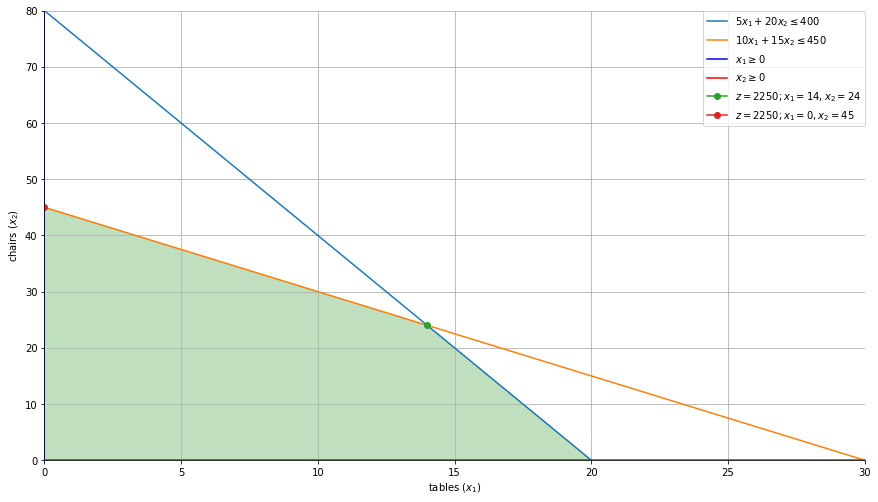

In [21]:
# Plot sol. space
x_1 = np.linspace(0, 100, 1000)
x_2 = np.linspace(0, 100, 1000)

# plot
fig, ax = plt.subplots()
fig.set_size_inches(14.7, 8.27)

# draw constraints
plt.plot(x_1, (400-(x_1*20))/5.0, label=r'$5 x_1 + 20 x_2 \leq 400$') # constraint 1
plt.plot(x_1, (450-(x_1*15))/10.0, label=r'$10 x_1 + 15 x_2 \leq 450$') # constraint 2
plt.axvline(0, color='b', label=r'$x_1 \geq 0$') # constraint 3
plt.axhline(0, color='r', label=r'$x_2 \geq 0$') # constraint 4

# Plot optimal solutions
plt.plot(14, 24, marker="o",label=r'$z = 2250 ; x_1 = 14, x_2 = 24$')
plt.plot(0, 45, marker="o",label=r'$z = 2250 ; x_1 = 0, x_2 = 45$')

plt.xlim((0, 30))
plt.ylim((0, 80))
plt.xlabel(r'tables ($x_1$)')
plt.ylabel(r'chairs ($x_2$)')

# fill in the fesaible region
plt.fill_between(x_1, np.minimum((400-(x_1*20))/5.0, (450-(x_1*15))/10.0), np.minimum((400-(x_1*20))/5.0, 0), 
where=x_1 >= 0,
color='green', alpha=0.25)
plt.legend(bbox_to_anchor=(1, 1), loc=1, borderaxespad=0.)

# Hide the right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.grid(True)
plt.show()

In [22]:
# MATH MODEL

# Define the problem data
revenue = [50,75]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 450

# Create the Gurobi model
model = gp.Model()

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.INTEGER, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# Add the constraint to force the alternative solution
c2 = model.addConstr(x[0] == 24, 'sol_force')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

    # START BLOCK: COMMENT IF THE PROBLEM IS A IP
    # print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    # if (abs(c1.Pi) > 1e-6):
    #     print('\t', c1.ConstrName, '\t:', c1.Pi)

    # # Print shadow prices of constraint c2
    # if (abs(c2.Pi) > 1e-6):
    #     print('\t', c2.ConstrName, '\t:', c2.Pi)

    # print('\nThe reduced costs for each decision variable are:')
    # Print the reduced costs of the decision variables
    # for v in model.getVars():
    #   print('\trc(',v.varName,')\t:', abs(v.rc))
    # END BLOCK: COMMENT IF THE PROBLEM IS A LP


    # retrieve and print number of solutions in solution pool 
    # (IMPORTANT: ONLY WORKS ON INTEGER PROBLEMS, LPs ARE NOT SUPPORTED BY GUROBI)
    # START BLOCK: COMMENT IF THE PROBLEM IS A LP
    solution_pool_size = model.getAttr('SolCount')
    print ("Solution pool contains {0} solutions".format(solution_pool_size))

    if (solution_pool_size > 0):
        # tell Gurobi to retrieve solution with worst objective value from solution pool
        model.params.solutionNumber = solution_pool_size - 1

        # print all variables with non-zero value
        for variable in model.getVars():
            value = variable.getAttr('Xn')
            if (value > 0):
                print("{0}: {1}".format(variable.getAttr('VarName'), value))
    # END BLOCK: COMMENT IF THE PROBLEM IS A LP

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 3 rows, 2 columns and 5 nonzeros
Model fingerprint: 0x90dd897c
Variable types: 0 continuous, 2 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [5e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [2e+01, 4e+02]
Presolve removed 3 rows and 2 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 1 (of 2 available processors)

Solution count 1: 2250 

Optimal solution found (tolerance 1.00e-04)
Best objective 2.250000000000e+03, best bound 2.250000000000e+03, gap 0.0000%

Optimal objective value: 2250.00
The factory need to produce 24.000000 chairs
The factory need to produce 14.000000 tables


### **Analysis**

- The solver gives you only one solution. However, one can either force a known solution, or explore the solution pool.

- Notice that the shadow price of the resource wood for this alternative optimal solution is zero. The marginal value of wood for this optimal solution is zero.

- Reduced cost of the non basic variable (tables) is zero. This means that if we produce more tables (and produce
less chairs) the revenue generated remains the same.

###**New business conditions** ☹

- The operations manager of the
furniture factory tells the data
scientist that she is negotiating
with the supplier of wood
to obtain an unlimited amount
of wood as long as the
factory procures at least 400
units of wood per week.

- In addition, the operations
manager is negotiating with
the union to obtain extra
workforce as long as the
factory hires at least 450 hours
of labor per week.


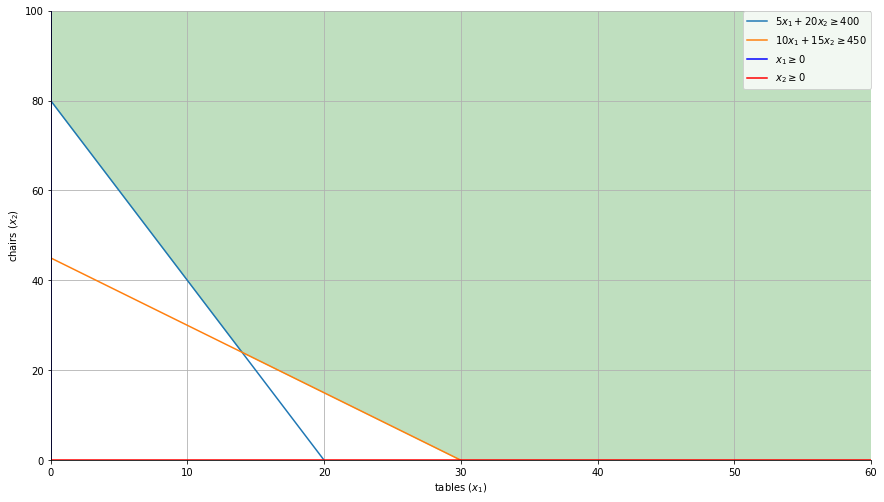

In [23]:
# Plot sol. space
x_1 = np.linspace(0, 100, 1000)
x_2 = np.linspace(0, 100, 1000)

# plot
fig, ax = plt.subplots()
fig.set_size_inches(14.7, 8.27)

# draw constraints
plt.plot(x_1, (400-(x_1*20))/5.0, label=r'$5 x_1 + 20 x_2 \geq 400$') # constraint 1
plt.plot(x_1, (450-(x_1*15))/10.0, label=r'$10 x_1 + 15 x_2 \geq 450$') # constraint 2
plt.axvline(0, color='b', label=r'$x_1 \geq 0$') # constraint 3
plt.axhline(0, color='r', label=r'$x_2 \geq 0$') # constraint 4


plt.xlim((0, 60))
plt.ylim((0, 100))
plt.xlabel(r'tables ($x_1$)')
plt.ylabel(r'chairs ($x_2$)')

# fill in the fesaible region
plt.fill_between(x_1, np.maximum((400-(x_1*20))/5.0, (450-(x_1*15))/10.0), np.maximum((400-(x_1*20))/5.0, 100), 
where=x_1 >= 0,
color='green', alpha=0.25)
plt.legend(bbox_to_anchor=(1, 1), loc=1, borderaxespad=0.)

# Hide the right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.grid(True)
plt.show()

### **Analysis**

- Notice that the polyhedron
defined by the feasible region
is **unbounded**.

- Clearly, the maximum of the
objective function is
unbounded, since the revenue
that we can make can be
arbitrarily large by increasing
the number of chairs (x1)
and/or the number of tables
(x2) as much as we want.
Recall, that we had assumed
that we sell everything that we
produce.

**Conclusion:** With unlimited
wood and labor, revenue
is unlimited.

In [24]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 450

# Create the Gurobi model
model = gp.Model()

# Add the decision variables
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) >= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) >= max_labor, 'labor_limit')

# Add the constraint to force the alternative solution
# c2 = model.addConstr(x[0] == 24, 'sol_force')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

    print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    if (abs(c1.Pi) > 1e-6):
        print('\t', c1.ConstrName, '\t:', c1.Pi)

    # Print shadow prices of constraint c2
    if (abs(c2.Pi) > 1e-6):
        print('\t', c2.ConstrName, '\t:', c2.Pi)

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 2 columns and 4 nonzeros
Model fingerprint: 0x8898dda3
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+02]
Presolve time: 0.01s

Solved in 0 iterations and 0.01 seconds (0.00 work units)
Infeasible or unbounded model


###**Responsability as Data Scientists** 

- Analyse the model and solution.
- Provide feedback to decision makers.
- Meet client demands (when possible).

- In this case, we (the data science team) recognized that it is unrealistic to assume that an infinite amount of chairs and tables can be sold.


### **New business conditions (defined by us)** 🐣

- We cans use predictive analytics techniques to determined the maximum number of chairs and tables that can be sold. This, to bound our solution space. 

- With the help of predictive analytics techniques we know that at most 200 chairs and 150 tables can
be sold.


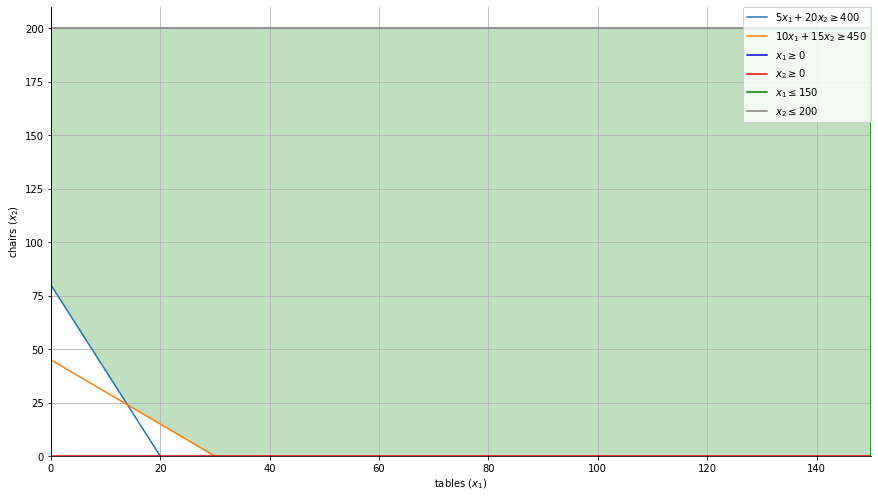

In [25]:
# Plot sol. space
x_1 = np.linspace(0, 200, 1000)
x_2 = np.linspace(0, 200, 1000)

# plot
fig, ax = plt.subplots()
fig.set_size_inches(14.7, 8.27)

# draw constraints
plt.plot(x_1, (400-(x_1*20))/5.0, label=r'$5 x_1 + 20 x_2 \geq 400$') # constraint 1
plt.plot(x_1, (450-(x_1*15))/10.0, label=r'$10 x_1 + 15 x_2 \geq 450$') # constraint 2
plt.axvline(0, color='b', label=r'$x_1 \geq 0$') # constraint 3
plt.axhline(0, color='r', label=r'$x_2 \geq 0$') # constraint 4
plt.axvline(150, color='g', label=r'$x_1 \leq 150$') # constraint 5
plt.axhline(200, color='grey', label=r'$x_2 \leq 200$') # constraint 6


plt.xlim((0, 150))
plt.ylim((0, 210))
plt.xlabel(r'tables ($x_1$)')
plt.ylabel(r'chairs ($x_2$)')

# fill in the fesaible region
plt.fill_between(x_1, np.maximum((400-(x_1*20))/5.0, (450-(x_1*15))/10.0), np.maximum((400-(x_1*20))/5.0, 200), 
where=x_1 >= 0,
color='green', alpha=0.25)
plt.legend(bbox_to_anchor=(1, 1), loc=1, borderaxespad=0.)

# Hide the right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.grid(True)
plt.show()

In [26]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 450

# New upper bound for the solution space
upBound = [200 , 150]

# Create the Gurobi model
model = gp.Model()

# Add the decision variables bounded
x = model.addVars(len(revenue), ub=upBound, vtype=GRB.CONTINUOUS, name='x')

# Add the decision variables not bounded
# x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) >= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) >= max_labor, 'labor_limit')

# Add the constraint to force the alternative solution
# c2 = model.addConstr(x[0] == 24, 'sol_force')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

    print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    if (abs(c1.Pi) > 1e-6):
        print('\t', c1.ConstrName, '\t:', c1.Pi)

    # Print shadow prices of constraint c2
    if (abs(c2.Pi) > 1e-6):
        print('\t', c2.ConstrName, '\t:', c2.Pi)

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 2 rows, 2 columns and 4 nonzeros
Model fingerprint: 0xcccd354e
Coefficient statistics:
  Matrix range     [5e+00, 2e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [2e+02, 2e+02]
  RHS range        [4e+02, 4e+02]
Presolve removed 2 rows and 2 columns
Presolve time: 0.01s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    2.1000000e+04   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.02 seconds (0.00 work units)
Optimal objective  2.100000000e+04

Optimal objective value: 21000.00
The factory need to produce 200.000000 chairs
The factory need to produce 150.000000 tables

The shadow prices for each constraint are:


###**New business conditions** ☹

- There is a memo from the CEO of the
furniture company saying that the new board of directors of the company requires a total revenue of at least \$4,500 per week.

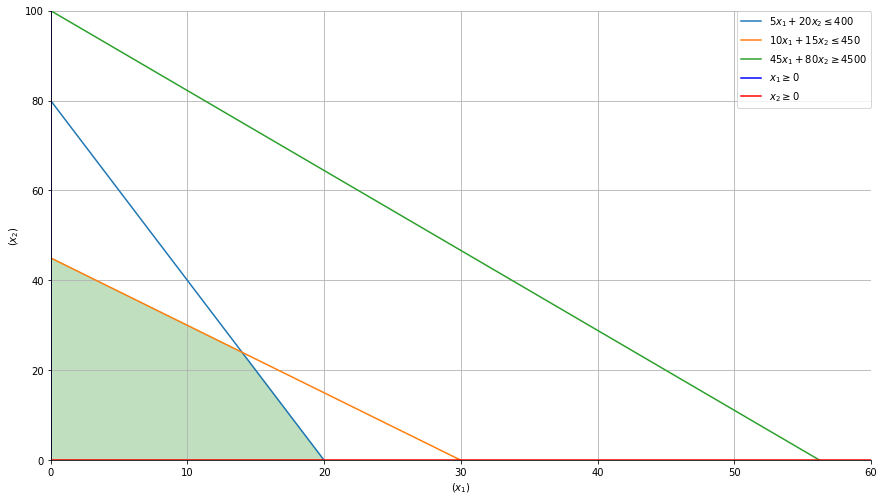

In [27]:
# Plot sol. space
x_1 = np.linspace(0, 100, 1000)
x_2 = np.linspace(0, 100, 1000)

# plot
fig, ax = plt.subplots()
fig.set_size_inches(14.7, 8.27)

# draw constraints
plt.plot(x_1, (400-(x_1*20))/5.0, label=r'$5 x_1 + 20 x_2 \leq 400$') # constraint 1
plt.plot(x_1, (450-(x_1*15))/10.0, label=r'$10 x_1 + 15 x_2 \leq 450$') # constraint 2
plt.plot(x_1, (4500-(80*x_1))/45.0, label=r'$45 x_1 + 80 x_2 \geq 4500$') # constraint 3
plt.axvline(0, color='b', label=r'$x_1 \geq 0$') # constraint 4
plt.axhline(0, color='r', label=r'$x_2 \geq 0$') # constraint 5


plt.xlim((0, 60))
plt.ylim((0, 100))
plt.xlabel(r'($x_1$)')
plt.ylabel(r'($x_2$)')

# fill in the fesaible region
plt.fill_between(x_1, np.minimum((400-(x_1*20))/5.0, (450-(x_1*15))/10.0), np.minimum((400-(x_1*20))/5.0, 0), 
where=x_1 >= 0,
color='green', alpha=0.25)
plt.legend(bbox_to_anchor=(1, 1), loc=1, borderaxespad=0.)


# Hide the right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.grid(True)
plt.show()

**Anaysis**

- Evidently, there are no points that satisfy all the constraints simultaneously. Hence this LP problem is **infeasible**.

In [28]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 450
# NEW CONSTRAINT: Imposed b the board of directors
min_revenue = 4500

# Create the Gurobi model
model = gp.Model()

# Add the decision variables not bounded
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the objective function
model.setObjective(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))), GRB.MAXIMIZE)

# Add the constraint for the maximum wood
c1 = model.addConstr(gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost))) <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2 = model.addConstr(gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost))) <= max_labor, 'labor_limit')

# Add the constraint for the maximum labor
c3 = model.addConstr(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))) >= min_revenue, 'min_revenue')

# Add the constraint to force the alternative solution
# c2 = model.addConstr(x[0] == 24, 'sol_force')

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))

    print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    if (abs(c1.Pi) > 1e-6):
        print('\t', c1.ConstrName, '\t:', c1.Pi)

    # Print shadow prices of constraint c2
    if (abs(c2.Pi) > 1e-6):
        print('\t', c2.ConstrName, '\t:', c2.Pi)

Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 3 rows, 2 columns and 6 nonzeros
Model fingerprint: 0xa88a9be5
Coefficient statistics:
  Matrix range     [5e+00, 8e+01]
  Objective range  [4e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+03]
Presolve time: 0.01s

Solved in 0 iterations and 0.01 seconds (0.00 work units)
Infeasible or unbounded model


### **Addressing infeasibility**

- Try to find human errors.
- Try to solve the infeasibility (if possible).
- Talk with the team.

**Options:**
- Sometimes we cannot just tell the  Board of Director that their
requirement of having a total
revenue of at least \$4,500 per
week is Infeasible !!!

- We need to identify the cause of infeasibility. In this case, we know that the cause of infeasibility is the limited capacity available of resources that does not allow the production of chairs and tables to reach the minimum level of total revenue.

- Talk wih the team to find potential solutions. In this case, we can call the
supplier of wood and talk with the labor union to agree to increase the supply at a cost (recourse action). We have that an extra unit of wood will cost \$20 and one hour of overtime of labor will cost \$30.

- Let's model it !

### **New model**

### Decision Variables

$x_{1} \geq 0$: Number of chairs.

$x_{2} \geq 0$: Number of tables.

### NEW Decision Variables
$y_{1} \geq 0$: Amount of extra wood  used. 

$y_{2} \geq 0$: Amount of extra labor used.


### Objective Function(s)

- **Max revenue**. We seek to maximize the total revenue.

\begin{equation}
\text{Max} \quad Z = 45 x_{1} + 80 x_{2} - 20 y_{1} - 30 y_{2}
\tag{0'}
\end{equation}

### New Constraints

- **Wood**

\begin{equation}
5 x_{1} + 20 x_{2} - 20 y_{1}\leq 400
\tag{1'}
\end{equation}

- **Labor**

\begin{equation}
10 x_{1} + 15 x_{2} - 30 y_{2}\leq 450
\tag{2'}
\end{equation}

- **Pos**

\begin{equation}
x_{1}, x_{2}, y_{1}, y_{2} \geq 0
\tag{3'}
\end{equation}

In [29]:
# MATH MODEL

# Define the problem data
revenue = [45,80]
wood_cost = [5,20]
labor_cost = [10,15]
max_wood = 400
max_labor = 450
# NEW CONSTRAINT: Imposed b the board of directors
min_revenue = 4500
extra_cost = [20,30]

# Create the Gurobi model
model = gp.Model()

# Add the decision variables not bounded
x = model.addVars(len(revenue), vtype=GRB.CONTINUOUS, name='x')

# Add the decision variables not bounded
y = model.addVars(len(extra_cost), vtype=GRB.CONTINUOUS, name='y')

# Add the objective function
ob1 = gp.quicksum(revenue[i]*x[i] for i in range(len(revenue)))

ob2 = gp.quicksum(extra_cost[i]*y[i] for i in range(len(extra_cost)))

ob = ob1 - ob2

model.setObjective(ob, GRB.MAXIMIZE)

# Add the constraint for the maximum wood

c1_1 = gp.quicksum(wood_cost[i]*x[i] for i in range(len(wood_cost)))

c1_2 = y[0]

c1 = model.addConstr(c1_1 - c1_2 <= max_wood, 'wood_limit')

# Add the constraint for the maximum labor
c2_1 = gp.quicksum(labor_cost[i]*x[i] for i in range(len(labor_cost)))

c2_2 = y[1]

c2 = model.addConstr(c2_1 - c2_2 <= max_labor, 'labor_limit')

# Add the constraint for the maximum labor
c3 = model.addConstr(gp.quicksum(revenue[i]*x[i] for i in range(len(revenue))) >= min_revenue, 'min_revenue')

# Add the constraint to force the alternative solution
# c2 = model.addConstr(x[0] == 24, 'sol_force')

model.write('mod.lp')

model.setParam('CutOff', -10000)
# model.resetParams()

# Optimize the model
model.optimize()

# Print the optimal solution
if model.status == GRB.OPTIMAL:
    print('\nOptimal objective value: %.2f' % model.objVal)
    for i in range(len(revenue)):
        if x[i].x > 0.5:
            if i == 0:
              print('The factory need to produce %f chairs' % (x[i].x))
            else:
              print('The factory need to produce %f tables' % (x[i].x))
    for i in range(len(extra_cost)):
        if y[i].x > 0.5:
            if i == 0:
              print('The factory need %f extra wood' % (y[i].x))
            else:
              print('The factory need %f extra labor' % (y[i].x))

    print('\nThe shadow prices for each constraint are:')
    # Print shadow prices of constraint c1
    if (abs(c1.Pi) > 1e-6):
        print('\t', c1.ConstrName, '\t:', c1.Pi)

    # Print shadow prices of constraint c2
    if (abs(c2.Pi) > 1e-6):
        print('\t', c2.ConstrName, '\t:', c2.Pi)

Set parameter Cutoff to value -10000
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (linux64)

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 3 rows, 4 columns and 8 nonzeros
Model fingerprint: 0x281508e5
Coefficient statistics:
  Matrix range     [1e+00, 8e+01]
  Objective range  [2e+01, 8e+01]
  Bounds range     [0e+00, 0e+00]
  RHS range        [4e+02, 4e+03]
Presolve time: 0.01s
Presolved: 3 rows, 4 columns, 8 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    1.0625000e+31   1.015625e+30   1.062500e+01      0s

Stopped in 4 iterations and 0.02 seconds (0.00 work units)
Model objective exceeds cutoff


### **Analysis**

- To meet the Board request requires 100 extra units of wood and 550 extra units of overtime. The optimal production plan is to produce only 100 chairs.
- The company will lose \$14,000 per week
- The Board request was proven not to be a good idea.


## **References**

This Python notebook includes an adaptation of the material presented in the **Introduction to Mathematical Programming** by **Gurobi Optimization, LLC.** (
https://www.gurobi.com/resources/lp-chapter-1-mathematical-programming/)